# Simulating survival datasets with SurvCraft

SurvCraft can simulate data using the **same survival models used for prediction**: an input module maps features to distribution parameters, and a survival module turns those parameters into conditional survival curves. `SurvivalPredictor` learns a model from observed outcomes; `SurvivalSimulator` uses a configured or initialized model and **samples its predicted curves to generate outcomes**. No fitting is required.

This notebook introduces simulation, fixed linear input maps, and FractalNoise baselines with proportional hazards (PH) and accelerated failure time (AFT) models. It also shows that a simulator can predict, while its scores on sampled outcomes need not be perfect.

For fine-tuning dataset properties, continue with [Simulation optimization with Optuna](Simulation%20optimization%20with%20Optuna.ipynb). Both notebooks run independently.

## Setup

Use Python 3.11+ and install the tutorial dependencies from the repository root:

```bash
python -m pip install -e ".[tutorials]"
python -m pip install survmetr
```

We use **survmetr** for concordance scores. No external datasets or optimization packages are needed. One PyTorch CPU thread is sufficient for these small examples.

In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from survmetr import AntoliniCIndexVecScorer

from survcraft import adapters as sc

torch.set_num_threads(1)
plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.grid": True})

pd.Series({name: version(name) for name in
           ["survcraft", "survmetr", "numpy", "torch"]}, name="Installed version")

survcraft    0.1.0
survmetr     0.1.0
numpy        2.2.6
torch        2.5.1
Name: Installed version, dtype: object

## 1. Sample from a survival model

We start with a Weibull model. Its two individual parameters are scale $\lambda(x)$ and shape $k(x)$, giving $S(t\mid x)=\exp[-(t/\lambda(x))^{k(x)}]$. These are the same Weibull parameters and survival computation used by a predictor.

The simulator's default input adapter is a fixed identity map. With two Weibull parameters, it takes the first two features as raw scale and shape; the survival module applies softplus to make them positive. The remaining features do not influence this example. Without an explicit survival adapter, `SurvivalSimulator()` uses an exponential distribution.

In [2]:
N_SAMPLES = 512
N_FEATURES = 8
OUTCOME_SEED = 1
X = np.random.default_rng(0).normal(size=(N_SAMPLES, N_FEATURES)).astype(np.float32)
times = np.linspace(0.0, 4.0, 1001)  # 1,000 sampling intervals.

basic = sc.SurvivalSimulator(survival=sc.WeibullSurvivalAdapter(), device="cpu")
y_basic = basic.simulate(X, times, seed=OUTCOME_SEED)

display(pd.DataFrame(y_basic).head())
print(f"Features: {X.shape}; target dtype: {y_basic.dtype}")
print(f"Censored: {(~y_basic['event']).mean():.1%}")

,event,time
0,True,0.446
1,False,4.000
2,True,0.014
3,False,4.000
4,True,0.230


Features: (512, 8); target dtype: [('event', '?'), ('time', '<f4')]
Censored: 7.4%


### Curves become events through sampling

For each individual, the simulator evaluates $F(t\mid x)=1-S(t\mid x)$ on the time grid. An interval receives probability $F(t_{j+1}\mid x)-F(t_j\mid x)$. It draws an interval and places an observed event at its midpoint. This is a grid approximation to sampling a continuous event time; a finer grid reduces rounding and event-time ties.

**The only censoring mechanism added by `simulate` is administrative censoring at the final grid point.** It does not draw independent dropout or random censoring times. Probability remaining outside the sampled intervals is assigned to censoring at that endpoint. For a distribution starting with $F(0)=0$, this is the survival probability at the horizon; any nonzero numerical $F(0)$ also enters the residual probability.

The structured target fields are `event=True` for an observed event and `event=False` for right censoring. For censored individuals, `time` is the end of follow-up, not an observed event time.

## 2. The simulator also predicts

A simulator exposes the prediction API: `predict_survival` returns conditional survival probabilities, `predict("failure", ...)` returns failure probabilities, and `predict("params", ...)` returns distribution parameters. Other modes depend on the survival module; Weibull also supports median event-time prediction.

The model is constructed on its first prediction or simulation and reused afterward. Changing the outcome seed produces new draws from the same curves; construct a fresh simulator when changing model configuration.

,scale,shape,predicted_median
0,0.757987,0.629275,0.423363
1,0.401948,0.248515,0.091975
2,0.457597,0.547451,0.234276
3,1.243622,0.741258,0.758495
4,0.616700,0.999697,0.427417
5,0.249917,1.712811,0.201774


Survival prediction shape: (6, 1001)
Failure probabilities at time 1: [0.6959278  0.71469843 0.78436196]


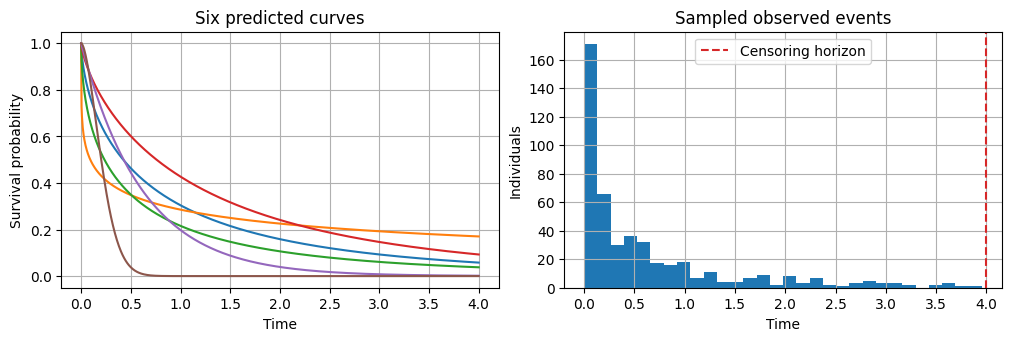

In [3]:
curves = basic.predict_survival(X[:6], times)
parameters = basic.predict("params", X[:6])
parameter_table = pd.DataFrame({name: values.ravel() for name, values in parameters.items()})
parameter_table["predicted_median"] = basic.predict("median_time", X[:6])
display(parameter_table)
print("Survival prediction shape:", curves.shape)
print("Failure probabilities at time 1:", basic.predict("failure", X[:3], 1.0))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
axes[0].plot(times, curves.T)
axes[0].set(xlabel="Time", ylabel="Survival probability", title="Six predicted curves")
axes[1].hist(y_basic["time"][y_basic["event"]], bins=30)
axes[1].axvline(times[-1], color="tab:red", linestyle="--", label="Censoring horizon")
axes[1].set(xlabel="Time", ylabel="Individuals", title="Sampled observed events")
axes[1].legend()
plt.show()

## 3. A linear layer designed for simulation

`LinearFunctionInputAdapter` constructs the simulation-specific `LinearFunctionInputModule`. It computes

$$\text{raw parameters}=XW+\text{shift},$$

with **fixed weights stored as buffers**, rather than parameters to be learned. This is useful beyond the default identity map: it gives controlled, reproducible relationships between features and event distributions without training a network.

- `mode="identity"` directly exposes features as raw parameters.
- `mode="random"` mixes features using seeded uniform weights in $[0,1)$.
- `multiplier` scales those weights, controlling feature-effect strength.
- `shift` moves all raw outputs, changing the typical distribution parameters.
- `use_first_n_feats` makes only a chosen prefix informative, leaving noise features for a later prediction problem.

A regular neural linear layer can also be used, but its default random initialization is intended for training. This adapter exposes the scenario controls directly. The affine relationship is in **raw parameter space**: positivity transformations and the survival distribution can still make the relationship between features and event times nonlinear. This fixed adapter is for simulation, not predictor fitting.

,raw_scale,raw_shape
feature_0,0.992513,1.536444
feature_1,0.176955,0.264061
feature_2,0.614846,1.268157
feature_3,0.000000,0.000000
feature_4,0.000000,0.000000
feature_5,0.000000,0.000000
feature_6,0.000000,0.000000
feature_7,0.000000,0.000000


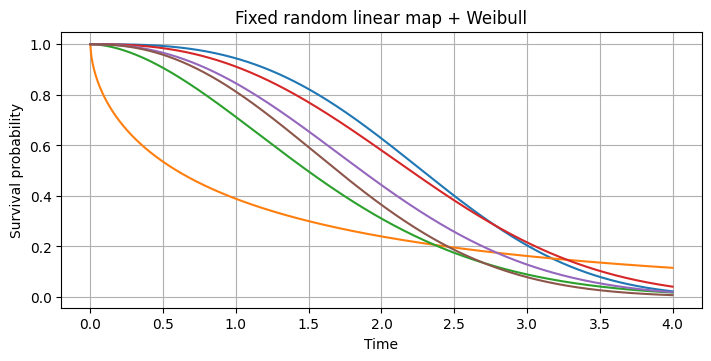

In [4]:
linear = sc.SurvivalSimulator(
    input=sc.LinearFunctionInputAdapter(
        mode="random", multiplier=2.0, shift=2.0,
        use_first_n_feats=3, seed=0,
    ),
    survival=sc.WeibullSurvivalAdapter(),
    device="cpu",
)
y_linear = linear.simulate(X, times, seed=OUTCOME_SEED)

# Inspect the known generating coefficients: the last five features have zero weight.
display(pd.DataFrame(
    linear.model_.input_module.linear_params.numpy(),
    columns=["raw_scale", "raw_shape"],
    index=[f"feature_{j}" for j in range(N_FEATURES)],
))

fig, ax = plt.subplots(layout="constrained")
ax.plot(times, linear.predict_survival(X[:6], times).T)
ax.set(xlabel="Time", ylabel="Survival probability", title="Fixed random linear map + Weibull")
plt.show()

### A neural input map works too

Simulation is not restricted to the fixed linear adapter. Here we compose `FeedForwardNetAdapter` and `LogNormalSurvivalAdapter`, just as for prediction. The network is randomly initialized and left untrained; a PyTorch seed fixes its weights when the model is first built.

This allows nonlinear simulation scenarios, but random network initialization does not automatically give strong feature effects or a useful censoring fraction. The fixed linear map is often easier to interpret and control.

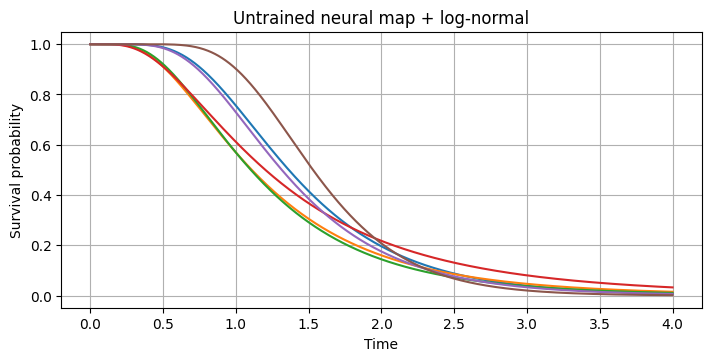

In [5]:
torch.manual_seed(10)
neural = sc.SurvivalSimulator(
    input=sc.FeedForwardNetAdapter(hidden_sizes=[16]),
    survival=sc.LogNormalSurvivalAdapter(),
    device="cpu",
)
y_neural = neural.simulate(X, times, seed=OUTCOME_SEED)

fig, ax = plt.subplots(layout="constrained")
ax.plot(times, neural.predict_survival(X[:6], times).T)
ax.set(xlabel="Time", ylabel="Survival probability", title="Untrained neural map + log-normal")
plt.show()

## 4. FractalNoise as a flexible baseline

`FractalNoiseSurvivalAdapter` creates a reproducible random, interpolated failure curve. Its `seed` changes the profile, `backbone_length` controls the initial backbone before refinement, and `max_time` sets the baseline time range. It provides an irregular baseline without choosing a named parametric distribution.

FractalNoise has **no individual distribution parameters**. Use it as a baseline under PH or AFT to introduce feature-dependent survival curves:

| Wrapper | Conditional survival | Effect of larger positive $r(x)$ |
|---|---|---|
| `ProportionalHazardSurvivalAdapter` | $S(t\mid x)=S_0(t)^{r(x)}$ | Multiplies the baseline hazard; earlier events |
| `AcceleratedFailureTimeSurvivalAdapter` | $S(t\mid x)=S_0(r(x)t)$ | Compresses time; earlier events |

Both wrappers obtain the single positive `relative_risk` parameter $r(x)$ from the input map. This AFT implementation uses an **inverse time scale**. The same FractalNoise seed lets us compare PH and AFT transformations of the same baseline.

FractalNoise is simulation-only and uses CPU interpolation without autograd. Its separate density interpolation is not the derivative of its failure curve, so we use its survival/failure curves for sampling rather than a density likelihood. A predictor for these data needs a trainable alternative baseline, such as StepExp.

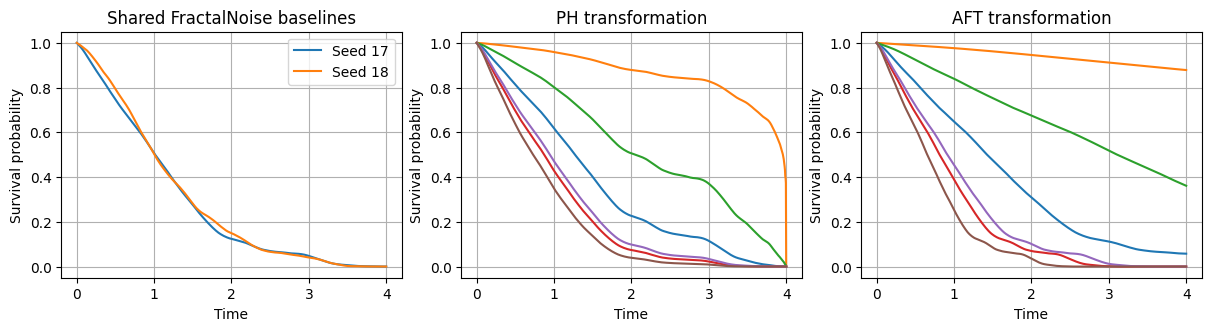

In [6]:
BASELINE_SEED = 17


def make_fractal_simulator(wrapper):
    """Combine a fixed feature effect with a random shared baseline."""
    return sc.SurvivalSimulator(
        input=sc.LinearFunctionInputAdapter(
            mode="random", multiplier=2.0, shift=0.0,
            use_first_n_feats=3, seed=0,
        ),
        survival=wrapper(
            baseline=sc.FractalNoiseSurvivalAdapter(
                max_time=4.0, backbone_length=5, seed=BASELINE_SEED,
            ),
            baseline_params=[],  # FractalNoise has zero raw baseline parameters.
        ),
        device="cpu",
    )


ph = make_fractal_simulator(sc.ProportionalHazardSurvivalAdapter)
aft = make_fractal_simulator(sc.AcceleratedFailureTimeSurvivalAdapter)
y_ph = ph.simulate(X, times, seed=OUTCOME_SEED)
y_aft = aft.simulate(X, times, seed=OUTCOME_SEED)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), layout="constrained")
for seed in [BASELINE_SEED, BASELINE_SEED + 1]:
    # Inspect the baseline alone; everyone shares this curve without a wrapper.
    baseline = sc.SurvivalSimulator(survival=sc.FractalNoiseSurvivalAdapter(
        max_time=4.0, backbone_length=5, seed=seed,
    ), device="cpu")
    axes[0].plot(times, baseline.predict_survival(X[:1], times)[0], label=f"Seed {seed}")
axes[0].legend()
for ax, simulator in zip(axes[1:], [ph, aft]):
    ax.plot(times, simulator.predict_survival(X[:6], times).T)
for ax, title in zip(axes, ["Shared FractalNoise baselines", "PH transformation", "AFT transformation"]):
    ax.set(xlabel="Time", ylabel="Survival probability", title=title)
plt.show()

## 5. Knowing the generating model does not give perfect scores

The simulator knows each individual's **conditional distribution**, not the random event time that will be drawn. Even correctly specified curves overlap, so a lower-risk individual can experience an earlier event by chance. Predictions on generated outcomes therefore need not be perfect.

We score the generating models with survmetr's time-dependent Antolini concordance. For comparable pairs, the person with the earlier event should have lower predicted survival at that time. About 0.5 indicates chance ranking; 1 indicates perfect ranking. Equal observed times are excluded by the scorer's default, and tied predictions get half credit.

This is a generating-model reference score, not a fitted predictor's test score. A learner trained on finite data may perform differently. Concordance also measures ranking, not calibration.

In [7]:
antolini = AntoliniCIndexVecScorer()
simulations = {
    "Identity + Weibull": (basic, y_basic),
    "Fixed linear + Weibull": (linear, y_linear),
    "Neural + log-normal": (neural, y_neural),
    "PH + FractalNoise": (ph, y_ph),
    "AFT + FractalNoise": (aft, y_aft),
}

results = []
for name, (simulator, y) in simulations.items():
    results.append({
        "Simulation": name,
        "Generating model Antolini": antolini(simulator, X, y),
        "Censoring fraction": float((~y["event"]).mean()),
    })
display(pd.DataFrame(results).set_index("Simulation").round(4))

# Same curves, different random outcomes; no new model is built.
resampled = []
for seed in [1, 2, 3]:
    y = linear.simulate(X, times, seed=seed)
    resampled.append({"Outcome seed": seed, "Antolini": antolini(linear, X, y),
                      "Censoring fraction": float((~y["event"]).mean())})
display(pd.DataFrame(resampled).set_index("Outcome seed").round(4))

,Generating model Antolini,Censoring fraction
Simulation,,
Identity + Weibull,0.6903,0.0742
Fixed linear + Weibull,0.7343,0.0898
Neural + log-normal,0.6018,0.0254
PH + FractalNoise,0.7474,0.0000
AFT + FractalNoise,0.7981,0.2461


,Antolini,Censoring fraction
Outcome seed,,
1,0.7343,0.0898
2,0.7254,0.0996
3,0.7066,0.0742


## 6. Follow-up and reproducibility

The observation window is a separate design choice. Keeping the same generating model, a longer follow-up usually reduces administrative censoring. All censored observations still occur at the final grid point; the simulator never adds dropout times.

In [8]:
follow_up = []
for horizon in [0.25, 1.0, 4.0]:
    grid = np.linspace(0.0, horizon, 1001)
    y = basic.simulate(X, grid, seed=OUTCOME_SEED)
    follow_up.append({
        "Horizon": horizon,
        "Censoring fraction": float((~y["event"]).mean()),
        "Observed censoring times": np.unique(y["time"][~y["event"]]).tolist(),
    })
display(pd.DataFrame(follow_up).set_index("Horizon"))

,Censoring fraction,Observed censoring times
Horizon,,
0.25,0.548828,[0.25]
1.00,0.259766,[1.0]
4.00,0.074219,[4.0]


Keep the different sources of randomness separate:

| Seed | What it controls |
|---|---|
| NumPy feature generator | Covariates $X$ |
| `LinearFunctionInputAdapter(seed=...)` | Fixed random feature-to-parameter weights |
| `torch.manual_seed(...)` before initialization | Neural input-map weights |
| `FractalNoiseSurvivalAdapter(seed=...)` | Shared baseline shape; construction resets Python's global random state |
| `simulate(..., seed=...)` | Sampled event intervals and censoring only |

Changing a mapping or baseline seed changes the underlying scenario. Changing only the outcome seed samples a new realization from that scenario. Record the configuration, grid, seeds, and package versions, and evaluate fresh features and outcome draws when assessing a simulation's properties.

These examples are deliberately not optimized. If you need a particular concordance level, censoring fraction, or event-time spread, the model parameters and seeds may need tuning. [The Optuna notebook](Simulation%20optimization%20with%20Optuna.ipynb) shows how to fine-tune those properties and check them on new data.